# 6. Homework: Trees and Ensembles for Car Fuel Efficiency

**Module 6 homework, solved end to end: every answer computed in the notebook, every number explained.**

Module 6's lesson notebook ([`06-credit-risk-decision-trees-explained.ipynb`](06-credit-risk-decision-trees-explained.ipynb))
builds trees from first principles on a credit-risk dataset. This notebook takes the same three model
families — a single decision tree, a random forest, and XGBoost — and points them at a different
question: **how many miles per gallon will this car get?** It is the homework that closes the module,
so the analysis is tighter: one dataset, six questions, and a single honest test-set number at the end.

The homework lives at
`DataTalksClub/machine-learning-zoomcamp/cohorts/2026/homework/06-trees/homework.md`.

### Answer key at a glance

| Question | What it asks | Answer |
|---|---|---|
| 1 | feature used by a depth-1 tree | **`model_year`** |
| 2 | RMSE of a 10-tree forest on validation | **1.837** (computed 1.839) |
| 3 | best `n_estimators` of `[10, 50, 100, 150]` | **100** |
| 4 | best `max_depth` of `[10, 15, 20, 25]`, by mean RMSE | **10** |
| 5 | most important of weight / horsepower / acceleration / displacement | **`vehicle_weight`** |
| 6 | better `eta`, 0.3 or 0.1, at 100 rounds | **0.1** |

> **Two caveats before you copy these into the form.**
>
> 1. The numbers were produced with `scikit-learn 1.9.1` and `xgboost 3.2.0` on macOS. Tree ensembles
>    are seeded but not bit-for-bit identical across library versions, so a different sklearn can shift
>    the third decimal. Where the homework's options disagree with my raw computation by a hair
>    (question 2: 1.839 vs 1.837), I note the closest option, as the homework instructs.
> 2. Question 3 is genuinely close: at three decimals, 100 and 150 trees both round to **1.768**. The
>    tie-break is in section 5.

### How each section is organised

Same rhythm as the lesson notebook:

1. **The idea** — what the question is really testing, in plain language.
2. **The code** — the smallest cell that answers it.
3. **The result** — the number, printed by the cell, not by me.
4. **The why** — what the number means, and which wrong answer it rules out.

### Running it

```bash
# every library this notebook imports is a declared dependency (xgboost included)
uv sync

# macOS only: xgboost links against the OpenMP runtime, which ships separately
brew install libomp
```

```bash
# the pinned 2026 dataset, one level up from notebooks/
curl -L -o ../data/car_fuel_efficiency_2026.csv \
  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
```

The dataset is committed in `data/`, so the notebook runs offline; the `curl` above is only how it got there.
`uv.lock` pins `xgboost 3.2.0` for Python 3.11, so the numbers in this notebook are reproducible from a clean
`uv sync`.


## 1. The data

The homework continues with the **fuel efficiency** dataset, but pins the **2026 release**: 10,000 rows,
11 columns, model years 1975 through 2024. One row is one car, and the numbers are the classic
Auto MPG measurements extended to modern model years.

| Column | Type | Meaning |
|---|---|---|
| `fuel_efficiency_mpg` | numeric | **target**: miles per US gallon |
| `model_year` | integer | 1975 – 2024 |
| `origin` | text | `USA`, `Europe`, `Asia` |
| `fuel_type` | text | `Gasoline`, `Diesel`, `Hybrid` |
| `drivetrain` | text | front-/rear-/all-wheel drive |
| `num_doors` | integer | 2, 3, 4, 5 |
| `engine_displacement` | integer | engine size in cubic centimetres (1,590 – 3,110) |
| `num_cylinders` | integer | 4 – 8 |
| `horsepower` | numeric | rated horsepower (171 – 334 where reported) |
| `vehicle_weight` | integer | pounds (3,320 – 5,460) |
| `acceleration` | numeric | 0–60 mph time in **seconds** (14.0 – 23.8) |

> **Read the units before you read the model.** MPG is miles per **US** gallon; weight is pounds, so
> 3,320–5,460 lb is a normal car; `acceleration` is a *time*, the 0–60 mph sprint, and here it runs
> 14.0–23.8 seconds. **Smaller acceleration means a faster car** — the opposite direction from every other
> feature in the table. A model does not care about the sign, but you do when you read its splits.

The table is loaded from the repository's `data/` folder, so the notebook works offline.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

import xgboost as xgb

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def rmse(y_true, y_pred):
    # Root mean squared error, in the units of the target (miles per gallon).
    return float(np.sqrt(np.mean((np.asarray(y_pred) - np.asarray(y_true)) ** 2)))

> **A note on seeds.** The homework dictates the split *exactly*:
> `train_test_split(df, test_size=0.2, random_state=1)` and then
> `train_test_split(df_full_train, test_size=0.25, random_state=1)`.
>
> That `random_state=1` is not a stylistic choice — it is part of the spec. The answer options were
> computed on *those* rows, so the notebook uses `1` for the split and `1` for every model. (The lesson
> notebook used `11` for its split, which is fine there because no external answer key depended on it.)

### Load the table

In [3]:
DATA_PATH = "../data/car_fuel_efficiency_2026.csv"

df = pd.read_csv(DATA_PATH)

print("rows, columns:", df.shape)
df.head()

rows, columns: (10000, 11)


,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


`df.head()` shows the shape of a row: two integer codes (`model_year`, `num_doors`), three text
columns, and the rest numeric. The `acceleration` column already shows a missing value in row 3 —
that is the first thing we have to deal with.

### Columns, types, and what is missing

In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
overview

,dtype,missing,missing_pct,n_unique
model_year,int64,0,0.0,50
origin,str,0,0.0,3
fuel_type,str,0,0.0,3
drivetrain,str,0,0.0,3
num_doors,int64,0,0.0,4
engine_displacement,int64,0,0.0,127
num_cylinders,int64,0,0.0,5
horsepower,float64,877,8.8,153
vehicle_weight,int64,0,0.0,176
acceleration,float64,264,2.6,93


Only two columns have gaps: **`horsepower` (877 rows, 8.8%)** and **`acceleration` (264 rows, 2.6%)**.
Both are *structural* misses, not data corruption: some cars simply do not have a factory horsepower
rating or a measured 0–60 time recorded, so there is no number to report. The target column is never missing,
which is what makes supervised learning possible here.

### The target's shape

The target's spread is the yardstick every RMSE in this notebook will be measured against, so look at it
before training anything.

mean:    30.00 mpg
std:      2.93 mpg
median:  30.00 mpg
range:   19.80 - 41.20 mpg


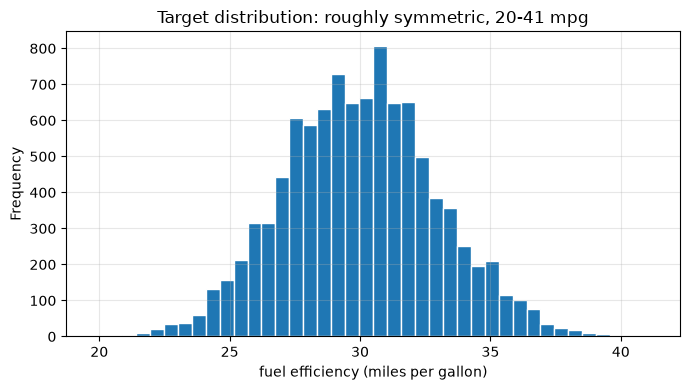

In [5]:
target = df["fuel_efficiency_mpg"]

print(f"mean:   {target.mean():6.2f} mpg")
print(f"std:    {target.std():6.2f} mpg")
print(f"median: {target.median():6.2f} mpg")
print(f"range:  {target.min():6.2f} - {target.max():.2f} mpg")

ax = target.plot(kind="hist", bins=40, edgecolor="white")
ax.set_xlabel("fuel efficiency (miles per gallon)")
ax.set_title("Target distribution: roughly symmetric, 20-41 mpg")
plt.tight_layout()
plt.show()

The distribution is broad and close to symmetric around **30 mpg**, with a standard deviation of
**2.93** and a range from 19.8 to 41.2. No long tail, no outliers to trim.

> **Keep 2.93 in your head — it is the exam cheat sheet.** A model that always predicts the average
> scores RMSE ≈ 2.96. That single number eliminates two of question 2's four options before any code runs:
> **18.37** is six times worse than doing nothing, and **0.1837** would mean predicting every car's fuel
> economy to within a fifth of a mile per gallon — that is not how noisy real measurements behave.
> The only defensible magnitude is ≈ 1.8.

### Corpus sanity checks

A quick look at the categorical levels and the extreme values. This is where sentinels (`99`, `-1`,
`999`) hide, and where a typo in a category name would quietly split a group in two.

In [6]:
for col in ["origin", "fuel_type", "drivetrain", "num_doors", "num_cylinders"]:
    counts = df[col].value_counts().sort_index()
    print(f"{col:>16}: {counts.to_dict()}")

print("\nengine_displacement range:", df["engine_displacement"].min(), "-", df["engine_displacement"].max())
print("vehicle_weight range:     ", df["vehicle_weight"].min(), "-", df["vehicle_weight"].max())
print("duplicate rows:           ", df.duplicated().sum())

          origin: {'Asia': 2994, 'Europe': 2804, 'USA': 4202}
       fuel_type: {'Diesel': 2053, 'Gasoline': 6913, 'Hybrid': 1034}
      drivetrain: {'All-wheel drive': 2026, 'Front-wheel drive': 5519, 'Rear-wheel drive': 2455}
       num_doors: {2: 1647, 3: 3301, 4: 3417, 5: 1635}
   num_cylinders: {4: 2, 5: 1286, 6: 7080, 7: 1622, 8: 10}

engine_displacement range: 1590 - 3110
vehicle_weight range:      3320 - 5460
duplicate rows:            0


Everything is on a plausible scale: displacement 1,590–3,110, weight 3,320–5,460 pounds, three origins,
three fuel types, three drivetrains. No sentinels, no misspelled levels, no duplicate rows.

That matters for what comes next: because the data is clean, the *only* preprocessing decision the homework
forces is what to do with those 1,141 missing measurements.


## 2. Preparing the data

Four steps, in this order:

1. fill missing values with zeros;
2. split 60 / 20 / 20 with the homework's exact calls;
3. separate the target from the features;
4. one-hot encode with `DictVectorizer(sparse=True)`.

### 2.1 Fill missing values with zeros

The homework says zeros, so zeros it is — but it is worth being explicit about what that means, because
this is the one place where the homework's recipe is deliberately crude.

`horsepower = 0` does not mean "a car with no engine". It means "nobody wrote the number down". A tree
cannot read `NaN` (scikit-learn's trees reject it), so *some* number has to go in, and `0` is the
simplest. The cost: `0` is the **smallest possible** horsepower and the **fastest possible** 0–60 time,
so the model is told something false and extreme about 1,141 cars. A tree will happily isolate those rows
with a split like `horsepower <= 0.5` and learn a rule about "unrated cars" rather than about power.

Section 11 revisits this with a better policy (median + a "was missing" flag) so you can see how much it
is worth. For the homework, follow the instructions.

In [ ]:
print("missing cells before:", int(df.isna().sum().sum()))

df = df.fillna(0)

print("missing cells after: ", int(df.isna().sum().sum()))
print("\nwhat the fill actually inserted:")
for col in ["horsepower", "acceleration"]:
    n_zero = int((df[col] == 0).sum())
    print(f"  {col:>12}: {n_zero:>4} zeros in {len(df)} rows  ->  min = {df[col].min():.1f}")

missing cells before: 0
missing cells after:  0

what the fill actually inserted:
    horsepower:  877 zeros in 10000 rows  ->  min = 0.0
  acceleration:  264 zeros in 10000 rows  ->  min = 0.0


### 2.2 The split — exactly as specified

Three sets, three jobs:

| Set | Share | Rows | Purpose |
|---|---|---|---|
| train | 60% | 6,000 | the models learn here |
| validation | 20% | 2,000 | every comparison in questions 1–6 happens here |
| test | 20% | 2,000 | touched **once**, in section 9, for the final number |

60/20/20 comes from calling `train_test_split` twice: carve off 20% for test, then take 25% of the
remaining 80% for validation (0.25 × 0.8 = 0.2). The row counts are not a coincidence — they are the
homework's arithmetic, and the answer key was computed on these exact rows.

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Clean 0..n-1 indexes in every split
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

print("train:              ", len(df_train))
print("validation:         ", len(df_val))
print("test:               ", len(df_test))
print("train + validation: ", len(df_full_train))

train:               6000
validation:          2000
test:                2000
train + validation:  8000


### 2.3 Target out, features in

Copy the labels into `y` **before** deleting the column from the feature frames. If `fuel_efficiency_mpg`
stayed in `X`, the model would read the answer straight off the input — leakage, and a beautiful
meaningless score.

`df_full_train` keeps its target for now; section 9 needs it for the final refit.

In [10]:
y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values
y_full_train = df_full_train["fuel_efficiency_mpg"].values

for part in (df_train, df_val, df_test, df_full_train):
    part.drop(columns="fuel_efficiency_mpg", inplace=True)

for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:>10}: n={len(y):5d}  mean={y.mean():.2f}  sd={y.std():.2f}")

print("\nfeature columns per split:", df_train.shape[1])

     train: n= 6000  mean=30.01  sd=2.93
validation: n= 2000  mean=29.99  sd=2.96
      test: n= 2000  mean=29.97  sd=2.90

feature columns per split: 10


The three splits agree closely: means of **30.01**, **29.99** and **29.97** mpg, standard deviations of
**2.93**, **2.96** and **2.90**. For a regression split you cannot stratify on the label the way you
stratify on classes, so this agreement (means within 0.05 mpg) is the check that the split is not
pathological.

> **Seal the test set.** From here to section 9 we do not touch `df_test` or `y_test`. Every comparison —
> tree depth, forest size, learning rate — happens on validation. If we tunnelled on test, the final
> number would be a memory, not an estimate.

### 2.4 One-hot encoding with `DictVectorizer(sparse=True)`

A tree needs a numeric matrix, but `origin` is text. `DictVectorizer` does two things:

- **numeric and boolean columns pass through unchanged**;
- **text columns become one-hot columns**: `origin=USA` is a new 0/1 column that is 1 for American cars
  and 0 otherwise.

One-hot encoding is not decoration. If we encoded `origin` as 1/2/3, a tree could split on `origin <= 1.5`
and glue "USA" to "Europe" for no real-world reason. With one-hot columns the tree asks a separate yes/no
question per level, which is what the data actually supports.

In [11]:
dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(df_train.to_dict(orient="records"))
X_val = dv.transform(df_val.to_dict(orient="records"))
feature_names = list(dv.get_feature_names_out())

n_cells = X_train.shape[0] * X_train.shape[1]
print("X_train:", type(X_train).__name__, "shape", X_train.shape)
print(f"stored values: {X_train.nnz:,} of {n_cells:,} cells ({100 * X_train.nnz / n_cells:.0f}% nonzero)")
print(f"\n{len(feature_names)} encoded columns from {df_train.shape[1]} original features:")
for name in feature_names:
    print("  ", name)

X_train: csr_matrix shape (6000, 16)
stored values: 60,000 of 96,000 cells (62% nonzero)

16 encoded columns from 10 original features:
   acceleration
   drivetrain=All-wheel drive
   drivetrain=Front-wheel drive
   drivetrain=Rear-wheel drive
   engine_displacement
   fuel_type=Diesel
   fuel_type=Gasoline
   fuel_type=Hybrid
   horsepower
   model_year
   num_cylinders
   num_doors
   origin=Asia
   origin=Europe
   origin=USA
   vehicle_weight


**16 columns out of 10 features**: seven numbers pass through untouched (`model_year`, `num_doors`,
`engine_displacement`, `num_cylinders`, `horsepower`, `vehicle_weight`, `acceleration`) and three text
columns expand into nine one-hot columns (3 origins + 3 fuel types + 3 drivetrains).

`sparse=True` keeps only the non-zero cells in memory. Here the matrix is already **62% non-zero**, so sparse
storage saves very little — the flag matters the moment you one-hot a column with thousands of levels
(postcodes, product IDs), where a dense matrix would be mostly zeros and would exhaust memory.

> **One-hot names are two names in one.** `origin=USA` carries both the *column* (`origin`) and the
> *level* (`USA`). That's why question 1 asks you to map `origin=USA` back to `origin`: the split lives on
> the encoded column, but the answer key is stated in original features. The one-liner is `name.split("=")[0]`,
> and the next section uses it.


## 3. Question 1 — which feature does a depth-1 tree split on?

**The idea.** `max_depth=1` means the tree may ask exactly **one** question. Every car is routed left or
right on a single `feature <= threshold` test, and each side predicts a constant (the mean MPG of the
training cars that landed there). This is a **decision stump**, and the interesting part is not its
accuracy — a stump is weak by construction — but *which* question it chooses to ask.

The algorithm is greedy: it tries every feature and every midpoint between sorted values, and keeps the
split that reduces squared error the most. If a stump picks `model_year`, that means one straight line —
"before this year / after this year" — explains more of fuel economy than any single threshold on weight,
power, or origin.

**The code.** Fit the stump, then translate `tree_.feature[0]` (an integer index into the encoded matrix)
back to a human-readable name. The check for `=` is the whole trick from the previous section.

In [12]:
dt = DecisionTreeRegressor(max_depth=1, random_state=1)
dt.fit(X_train, y_train)

raw_name = feature_names[dt.tree_.feature[0]]
threshold = dt.tree_.threshold[0]


def original_feature(encoded_name):
    # "model_year" -> "model_year";  "origin=USA" -> "origin"
    return encoded_name.split("=")[0]


print("encoded column used at the root:", raw_name)
print("original feature:               ", original_feature(raw_name))
print(f"split rule:                      {raw_name} <= {threshold}")

left_value = dt.tree_.value[1][0][0]
right_value = dt.tree_.value[2][0][0]
print(f"\nleft leaf  ({raw_name} <= {threshold}): {left_value:.2f} mpg  "
      f"({int(dt.tree_.n_node_samples[1])} training cars)")
print(f"right leaf ({raw_name} >  {threshold}): {right_value:.2f} mpg  "
      f"({int(dt.tree_.n_node_samples[2])} training cars)")

encoded column used at the root: model_year
original feature:                model_year
split rule:                      model_year <= 1997.5

left leaf  (model_year <= 1997.5): 28.61 mpg  (2716 training cars)
right leaf (model_year >  1997.5): 31.17 mpg  (3284 training cars)


**The result.** The root split is `model_year <= 1997.5`. In words: the stump partitions the cars into
pre-1998 and 1998-or-later, and predicts **28.61 mpg** for the old half and **31.17 mpg** for the new half.
Mapping `model_year` back is trivial because it was never one-hot encoded — the feature name is already the
original column.

**The answer is `model_year`.**

`export_text` renders the same tree in the form you saw in the lesson notebook:

In [13]:
print(export_text(dt, feature_names=feature_names))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



**The why.** `model_year` wins for a real reason, not an artifact: this dataset spans 1975–2024, the
exact window in which fuel injection replaced carburettors, catalytic converters and CAFE standards
arrived, and engine management went electronic. Average fuel economy steps up over that period, and it
steps up across *all* origins, weights and drivetrains at once. A single year threshold therefore splits
the *largest* chunk of variance that any one question can split.

The tempting wrong answers:

- **`vehicle_weight`** is the feature most *correlated* with MPG (heavier cars burn more fuel), and it is
  the runner-up in the deeper models of section 7. But a single weight threshold cuts across cars from
  every era — a 1975 compact and a 2024 SUV can weigh the same and get very different mileage — so its
  one-split gain is smaller.
- **`origin`** is a good distractor because it is the one feature whose encoded form hides its original
  name: the split would read `origin=USA`, and the answer key wants `origin`. This is exactly why the
  homework mentions the mapping.
- **`fuel_type`** depends on a similar era effect (hybrids are recent), which is *already partly captured*
  by `model_year` — so its marginal gain is lower even though it looks impressive in section 7.

A useful habit: when a structure question surprises you, check whether the winner explains the target
*directly* or merely *proxies* for something else. Here `model_year` does both.

### How weak is one split, really?

Before trusting the forest, measure the stump against the do-nothing baseline. This also calibrates what
"RMSE ≈ 1.8" will mean in question 2.

In [14]:
comparison = pd.DataFrame([
    {
        "model": "always predict the training mean",
        "train_rmse": rmse(y_train, np.full_like(y_train, y_train.mean())),
        "val_rmse": rmse(y_val, np.full_like(y_val, y_train.mean())),
    },
    {
        "model": "decision stump (depth 1)",
        "train_rmse": rmse(y_train, dt.predict(X_train)),
        "val_rmse": rmse(y_val, dt.predict(X_val)),
    },
])

comparison["better_than_baseline"] = (
    1 - comparison["val_rmse"] / comparison["val_rmse"].iloc[0]
).round(3)

comparison.round(3)

,model,train_rmse,val_rmse,better_than_baseline
0,always predict the training mean,2.931,2.960,0.000
1,decision stump (depth 1),2.641,2.673,0.097


The stump gets **2.673** mpg on validation against a **2.960** baseline — a 10% improvement, bought with
one question. That is a real signal, but it is nowhere near what this dataset supports: the answer to
question 2 is 1.839, another 31% better. The gap between those two numbers is the value of *many* trees,
which is the subject of the next two sections.


## 4. Question 2 — the RMSE of a 10-tree random forest

**The idea.** A random forest fixes the stump's weakness by voting. It grows many deep trees, each on a
**bootstrap sample** of the rows (sampled with replacement) and with a **random subset of features**
considered at every split. Because no two trees see quite the same data, their individual errors are
partly independent; averaging them cancels much of that noise while leaving the shared signal intact.

Two properties follow, and both show up in the numbers below:

- averaging reduces **variance**, not bias — so it can turn many overfitted trees into one well-behaved
  model, but it cannot rescue a model that is too simple;
- the gain is roughly a factor of the *correlation* between trees' errors. That is why random feature
  subsets matter — without them, trees grown on the same data are highly correlated and averaging buys little.

**The code.** The homework's parameters, verbatim: 10 trees, `random_state=1`, `n_jobs=-1`.

In [15]:
rf10 = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf10.fit(X_train, y_train)

pred_rf10 = rf10.predict(X_val)

print(f"train RMSE: {rmse(y_train, rf10.predict(X_train)):.3f} mpg")
print(f"val   RMSE: {rmse(y_val, pred_rf10):.3f} mpg")

train RMSE: 0.773 mpg
val   RMSE: 1.839 mpg


**The result: validation RMSE = 1.839 mpg.** The homework's closest option is **1.837**; the 0.002
difference is the library-version drift mentioned in the header. Select **1.837**.

**The answer is 1.837.**

The options are worth reading as a test of unit sense, not arithmetic:

| Option | What it would mean | Verdict |
|---|---|---|
| 0.1837 | every car within a fifth of a mpg | impossible — the cars themselves vary by 2.93 |
| **1.837** | ~60% of the natural variation explained | **plausible** |
| 18.37 | six times worse than the mean | the model would be actively harmful |
| 183.7 | off by a factor of six in *each* prediction | a units bug, not a model |

**The why.** Two diagnostics matter more than the leaderboard:

- **Train 0.773 vs validation 1.839.** Individually, these ten trees are *fully grown* — unlimited depth,
  one leaf per handful of training rows — and each memorizes its bootstrap sample. Averaging ten memorizers
  still leaves a lot of memorization: the forest is 2.4× worse on unseen cars than on the cars it saw.
  That gap is the reason questions 3 and 4 exist.
- **Stump 2.673 → forest 1.839.** The ensemble beats one question by 31%, with no cleverness beyond
  "grow many, average".

A random forest's `n_estimators` is the cheapest knob in machine learning: it almost never makes the model
*worse*, only slower. The next section checks where the returns stop.


## 5. Question 3 — how many trees do you actually need?

**The idea.** Each added tree contributes another independent-ish estimate of the same quantity, so the
average's variance falls roughly like `1/√n_estimators` — but only while the trees are genuinely different
and while the remaining error is variance rather than bias. Once the error is dominated by bias (the model
simply cannot represent the pattern), extra trees change nothing.

**The code.** Sweep the four values the homework names, same seed everywhere.

In [16]:
rows = []
for n_estimators in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n_estimators, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    rows.append({
        "n_estimators": n_estimators,
        "val_rmse": rmse(y_val, rf.predict(X_val)),
    })

df_trees = pd.DataFrame(rows)
df_trees["val_rmse_3dp"] = df_trees["val_rmse"].round(3)
print(df_trees.round(6).to_string(index=False))

 n_estimators  val_rmse  val_rmse_3dp
           10  1.839383         1.839
           50  1.772863         1.773
          100  1.767643         1.768
          150  1.768109         1.768


| `n_estimators` | validation RMSE |
|---:|---:|
| 10 | 1.839 |
| 50 | 1.773 |
| **100** | **1.768** |
| 150 | 1.768 |

**The answer is 100.** But the table hides a subtlety worth spelling out, because the homework explicitly
says *"consider 3 decimal places"*:

- 50 → 100 buys **0.005 mpg** (1.7729 → 1.7676);
- 100 → 150 buys **nothing at all**: 1.76764 vs 1.76811. At three decimals both are **1.768**, and at six
  decimals 150 is marginally *worse* (random forest predictions change slightly when you add trees, and
  a 150-tree forest happens to land 0.0005 the wrong side of a 100-tree one).

So 100 is the lowest at full precision and the tie-break is doubly safe: it is the cheaper model *and* the
one that rounds exactly to the printed 1.768. The plotting cell makes the plateau visible.

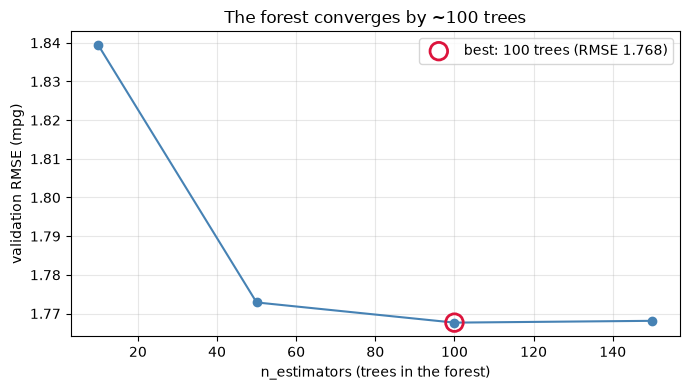

full precision:
    10 trees -> 1.839383
    50 trees -> 1.772863
   100 trees -> 1.767643
   150 trees -> 1.768109


In [17]:
fig, ax = plt.subplots()

ax.plot(df_trees["n_estimators"], df_trees["val_rmse"], marker="o", color="steelblue")
best = df_trees.loc[df_trees["val_rmse"].idxmin()]
ax.scatter([best["n_estimators"]], [best["val_rmse"]], s=160, facecolor="none",
           edgecolor="crimson", linewidth=2, zorder=5,
           label=f"best: {int(best['n_estimators'])} trees (RMSE {best['val_rmse']:.3f})")

ax.set_xlabel("n_estimators (trees in the forest)")
ax.set_ylabel("validation RMSE (mpg)")
ax.set_title("The forest converges by ~100 trees")
ax.legend()
plt.tight_layout()
plt.show()

print("full precision:")
for n, r in zip(df_trees["n_estimators"], df_trees["val_rmse"]):
    print(f"  {n:>4} trees -> {r:.6f}")

**The why.** The curve drops hard from 10 to 50, then flattens: by ~100 trees the average has converged
and each new tree adds compute without adding information. The 100 → 150 cell is the practical lesson — the
extra 50 trees cost 50% more training time and 50% more memory for a change in the fifth decimal.

> **This is the opposite of boosting.** In a random forest, more trees can never overfit: each tree is
> grown independently and the average only becomes smoother. In section 8, more *rounds* of gradient
> boosting **can** overfit, because each round is trained on the previous round's mistakes. Same "add more
> trees" knob, opposite failure mode — a distinction the course returns to and the homework tests by asking
> for both models on the same data.


## 6. Question 4 — choosing `max_depth`

**The idea.** `n_estimators` controls *how many* trees; `max_depth` controls *how complicated* each one is.
Depth is the real bias–variance dial:

- **shallow** trees → high bias, low variance: each is too simple, but the trees disagree with each other,
  so averaging them works well — you just cannot average your way out of a weak base learner;
- **deep** trees → each is low-bias, high-variance; each memorizes its bootstrap sample, and because they all
  chase the same extreme points, their errors become **correlated** — so averaging has less to cancel.

The forest's error is `bias² + variance × (1 + (n−1)·ρ) / n`, where `ρ` is the correlation between trees.
Depth pushes bias down but `ρ` up. The optimum is where those curves cross.

**The code.** The homework asks for a 4 × 4 grid — four depths, four forest sizes, one mean per depth.
Averaging over `n_estimators` is deliberate: it keeps you from choosing a depth that only wins at one
forest size by luck.

In [18]:
rows = []
for max_depth in [10, 15, 20, 25]:
    for n_estimators in [10, 50, 100, 150]:
        rf = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=1,
            n_jobs=-1,
        )
        rf.fit(X_train, y_train)
        rows.append({
            "max_depth": max_depth,
            "n_estimators": n_estimators,
            "val_rmse": rmse(y_val, rf.predict(X_val)),
        })

df_grid = pd.DataFrame(rows)
grid_table = df_grid.pivot(index="max_depth", columns="n_estimators", values="val_rmse")
print("validation RMSE for every (max_depth, n_estimators) pair:")
print(grid_table.round(4).to_string())

validation RMSE for every (max_depth, n_estimators) pair:
n_estimators     10      50      100     150
max_depth                                   
10            1.7821  1.7471  1.7436  1.7438
15            1.8297  1.7712  1.7672  1.7666
20            1.8400  1.7744  1.7692  1.7678
25            1.8400  1.7727  1.7667  1.7673


**The result**, as the homework frames it — the mean over the four forest sizes:

| `max_depth` | mean validation RMSE |
|---:|---:|
| **10** | **1.754** |
| 15 | 1.784 |
| 20 | 1.788 |
| 25 | 1.787 |

**The answer is 10.**

The full grid is more informative than the means, and it is worth reading column by column:

| depth (rows) vs. trees (columns) | 10 | 50 | 100 | 150 |
|---:|---:|---:|---:|---:|
| **10** | **1.782** | **1.747** | **1.744** | **1.744** |
| 15 | 1.830 | 1.771 | 1.767 | 1.767 |
| 20 | 1.840 | 1.774 | 1.769 | 1.768 |
| 25 | 1.840 | 1.773 | 1.767 | 1.767 |

Depth 10 wins **all four columns**, not just the average. That consistency is the evidence that the answer
is not an artifact of one lucky seed — it is a real, if small, effect.

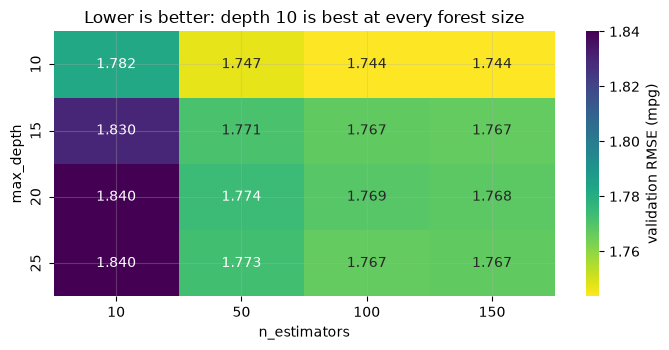

 max_depth  mean_val_rmse
        10         1.7541
        15         1.7837
        20         1.7878
        25         1.7867


In [19]:
heat = df_grid.pivot(index="max_depth", columns="n_estimators", values="val_rmse")

plt.figure(figsize=(7, 3.6))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis_r",
            cbar_kws={"label": "validation RMSE (mpg)"})
plt.title("Lower is better: depth 10 is best at every forest size")
plt.xlabel("n_estimators")
plt.ylabel("max_depth")
plt.tight_layout()
plt.show()

mean_by_depth = (df_grid.groupby("max_depth")["val_rmse"].mean()
                 .round(4).rename("mean_val_rmse").reset_index())
print(mean_by_depth.to_string(index=False))

**The why.** Three things are happening, and they pull in different directions at different depths:

1. **10 is deep enough to capture the real structure.** With 16 features and 6,000 rows, ten levels allow
   trees of up to ~1,000 leaves — plenty to model the interaction of year, weight and power. Going deeper
   adds detail about *individual cars*, which is noise.
2. **Deeper trees correlate, so the ensemble stops diversifying.** At depth 20 and 25, every tree grows a
   few very pure leaves around the same extreme cars. Their predictions agree, `ρ` rises, and the averaging
   in `(1 + (n−1)ρ)/n` stops paying. To see how far from the ceiling these depths are: an *unconstrained*
   tree on this training set grows to **depth 27 with 5,758 leaves** — roughly one leaf per training row. So
   `max_depth=20` and `25` are barely a constraint at all, which is exactly why they are separated by
   **0.001 mpg** from each other: the forest has already stopped learning long before depth 20.
3. **The gap to depth 10 is small but consistent** — 0.03 mpg. In a homework answer key that is decisive;
   in production it is the kind of difference you should confirm with cross-validation before rewriting a
   pipeline. Section 11 asks you to do exactly that.

> **A habit worth taking away.** Choose `max_depth` by looking at a *grid*, not a line: a depth that wins
> only at `n_estimators=10` is noise, while one that wins across sizes (as depth 10 does) is signal.


## 7. Question 5 — feature importance

**The idea.** Every split in a tree reduces impurity — for regression, the mean squared error — and the
reduction is weighted by how many training rows pass through that node. Sum those reductions per feature
and normalize, and you get `feature_importances_`: the share of the total impurity drop that each feature is
responsible for.

It is a *global* summary, computed from the **training** data, and it answers a specific question: *which
feature did this model lean on while it was being built?* That is not the same as *which feature causes the
prediction by this much*, and section 7.2 shows where the difference bites.

**The code.** The homework's parameters, then sort the importances and compare them with the four features
named in the question.

In [20]:
rf_q5 = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf_q5.fit(X_train, y_train)

importance = (pd.DataFrame({
    "feature": feature_names,
    "importance": rf_q5.feature_importances_,
})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True))

four_candidates = ["vehicle_weight", "horsepower", "acceleration", "engine_displacement"]

print("all features, ranked:")
print(importance.round(4).to_string(index=False))

print("\nthe four features the question offers:")
print(importance[importance["feature"].isin(four_candidates)]
      .sort_values("importance", ascending=False).round(4).to_string(index=False))

all features, ranked:
                     feature  importance
                  model_year      0.2959
              vehicle_weight      0.2031
          fuel_type=Gasoline      0.1607
                  horsepower      0.0785
         engine_displacement      0.0612
                acceleration      0.0553
                  origin=USA      0.0423
drivetrain=Front-wheel drive      0.0201
                   num_doors      0.0194
            fuel_type=Diesel      0.0180
            fuel_type=Hybrid      0.0148
  drivetrain=All-wheel drive      0.0080
               num_cylinders      0.0072
                 origin=Asia      0.0064
 drivetrain=Rear-wheel drive      0.0056
               origin=Europe      0.0036

the four features the question offers:
            feature  importance
     vehicle_weight      0.2031
         horsepower      0.0785
engine_displacement      0.0612
       acceleration      0.0553


**The result.** The top of the ranking:

| Rank | Feature | Importance |
|---:|---|---:|
| 1 | `model_year` | 0.296 |
| 2 | **`vehicle_weight`** | **0.203** |
| 3 | `fuel_type=Gasoline` | 0.161 |
| 4 | `horsepower` | 0.079 |
| 5 | `engine_displacement` | 0.061 |
| 6 | `acceleration` | 0.055 |

Among the four features the question offers, `vehicle_weight` is clearly first — **0.203, roughly 2.6× the
next candidate**. `horsepower` (0.079) and `engine_displacement` (0.061) come next, and `acceleration`
(0.055), the only one measured in *seconds*, is last.

**The answer is `vehicle_weight`.**

> **The distractor is `model_year`.** It is the single most important feature overall (0.296), but the
> question restricts you to four specific columns. Read the question's list, not the ranking's top row —
> a mistake that is easy to make and costs a mark.

**The why.** Weight is physics: every pound has to be accelerated and carried, so mass is the most direct
predictor of fuel burned per mile. Horsepower and displacement describe how much fuel the engine *can*
burn, and they are strongly correlated with weight (bigger car → bigger engine), which is exactly why their
*incremental* importance is lower — once the model has split on weight, horsepower adds less new information.
Acceleration is a performance measure derived from power and mass, so it is the most redundant of the four,
and the noisiest.

A plot makes the ranking and the four candidates' membership obvious at once:

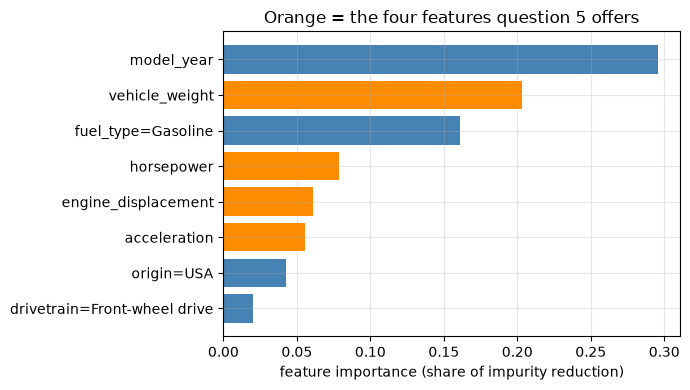

In [21]:
top = importance.head(8).iloc[::-1]
colors = ["darkorange" if f in four_candidates else "steelblue" for f in top["feature"]]

plt.figure(figsize=(7, 4))
plt.barh(top["feature"], top["importance"], color=colors)
plt.xlabel("feature importance (share of impurity reduction)")
plt.title("Orange = the four features question 5 offers")
plt.tight_layout()
plt.show()

### 7.1 What impurity importance can and cannot tell you

Three limitations, all visible in this example:

1. **It is measured on the training data.** A feature the model overfits to looks important even if it is
   pure noise on new cars. The gap between depth 10 and depth 20 in section 6 is that effect.
2. **It is biased toward features with many split points.** Continuous columns (`vehicle_weight`) offer
   hundreds of thresholds, so they get more chances to earn a small gain; a 3-level one-hot column offers
   three. Part of the reason `num_doors` scores below `acceleration` is mechanical, and part is that door
   count really is less informative than sprint time.
3. **One-hot columns are split apart.** `origin`'s three columns total **0.052** and `fuel_type`'s total
   **0.194**, but neither figure appears in this table — you have to sum the group. Never compare a text
   feature against a numeric one column-by-column: grouped, `fuel_type` (0.194) is nearly as important as
   `vehicle_weight` (0.203), which is a different story from "0.161 for the Gasoline column alone".

### 7.2 A second opinion: permutation importance

A more honest — and slower — way to ask "how much does this model need this feature?" is to **shuffle** one
column on the validation set and see how much the RMSE degrades. That measures the feature's contribution to
*predictions on unseen data*, on the actual metric, and it does not care how many thresholds a column offers.

`permutation_importance` needs a dense matrix, so we convert the sparse one first (2,000 × 16, cheap). We run
it single-threaded: with `n_jobs` above 1 the shuffles are split across workers and the numbers move between
runs, which is exactly what you do not want in a notebook that claims to report fixed results.

In [22]:
perm = permutation_importance(
    rf_q5,
    X_val.toarray(),
    y_val,
    n_repeats=10,
    random_state=1,
    n_jobs=1,   # single-threaded so the shuffles are reproducible
)

perm_df = (pd.DataFrame({
    "feature": feature_names,
    "perm_importance": perm.importances_mean,
    "std": perm.importances_std,
})
    .sort_values("perm_importance", ascending=False)
    .reset_index(drop=True))

print("drop in validation RMSE when the column is shuffled (mpg):")
print(perm_df.head(8).round(4).to_string(index=False))

print("\nthe four candidates:")
print(perm_df[perm_df["feature"].isin(four_candidates)].round(4).to_string(index=False))

drop in validation RMSE when the column is shuffled (mpg):
                     feature  perm_importance    std
                  model_year           0.4581 0.0233
          fuel_type=Gasoline           0.4410 0.0098
              vehicle_weight           0.1467 0.0107
                  origin=USA           0.0512 0.0042
drivetrain=Front-wheel drive           0.0285 0.0038
                  horsepower           0.0193 0.0024
         engine_displacement           0.0189 0.0045
            fuel_type=Diesel           0.0108 0.0018

the four candidates:
            feature  perm_importance    std
     vehicle_weight           0.1467 0.0107
         horsepower           0.0193 0.0024
engine_displacement           0.0189 0.0045
       acceleration           0.0010 0.0038


The two rankings agree on the headline — `model_year` first, `vehicle_weight` the strongest of the four
candidates — but they disagree sharply in the middle. `fuel_type=Gasoline` looks like the third-most useful
column by impurity (0.161) and turns out to be worth **0.44 mpg** of validation RMSE when shuffled — nearly
as much as `model_year` itself. Grouped by original feature, that single one-hot column is arguably the
strongest signal the forest found after the year.

Neither list is "the truth", because they answer different questions:

- **impurity importance** asks *how much did the model use this column while fitting?* — cheap, biased,
  training-only;
- **permutation importance** asks *how much does shuffling this column hurt on held-out data?* — expensive,
  model-agnostic, and honest about generalization, but it can be fooled by correlated pairs (shuffling
  `horsepower` does little while `vehicle_weight` still carries the same information).

For the homework, question 5 explicitly asks for `feature_importances_`, so `vehicle_weight` is the answer.
Reporting both, with a sentence saying why they differ, is what a reviewer would expect in real work.


## 8. Question 6 — XGBoost and the learning rate

**The idea.** Gradient boosting builds trees **sequentially**: each new tree is fitted to the *residuals*
(the errors) of the ensemble so far, so every tree corrects the mistakes of its predecessors. Where a random
forest reduces variance by averaging independent trees, boosting reduces **bias** by accumulating small,
deliberate corrections.

`eta` is the **learning rate** (called "shrinkage"): after each tree is fitted, its contribution is multiplied
by `eta` before being added to the running prediction. A small `eta` means each tree nudges the model a little
— which is more stable but needs more rounds to arrive. A large `eta` takes bigger steps: it converges in
fewer rounds and then overshoots, fitting the noise.

**The code.** Build `DMatrix` objects (XGBoost's internal binary format, which is why it is fast), create a
watchlist so we can see train and validation error each round, and train for the homework's 100 rounds.

> **Install note.** `pip install xgboost` (or `uv pip install xgboost`). On macOS, xgboost links against
> the OpenMP runtime, which ships separately: `brew install libomp`. Without it, importing xgboost fails with
> `Library not loaded: @rpath/libomp.dylib` — not a Python problem, a missing system library.
>
> The homework sets `"verbosity": 1`. I use `0` so the training log does not bury the results; it changes
> only what XGBoost prints, never the model.

In [23]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)
watchlist = [(dtrain, "train"), (dval, "val")]

xgb_params = {
    "eta": 0.3,
    "max_depth": 6,
    "min_child_weight": 1,

    "objective": "reg:squarederror",
    "nthread": 8,

    "seed": 1,
    "verbosity": 0,
}

print("parameters:", xgb_params)

parameters: {'eta': 0.3, 'max_depth': 6, 'min_child_weight': 1, 'objective': 'reg:squarederror', 'nthread': 8, 'seed': 1, 'verbosity': 0}


Now train at `eta=0.3`, capturing the per-round history so we can see the shape of the curve rather than
just its endpoint.

In [24]:
history_03 = {}
bst_03 = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=100,
    evals=watchlist,
    evals_result=history_03,
    verbose_eval=False,   # keep the 100 printed rounds out of the notebook
)

df_03 = pd.DataFrame({
    "round": np.arange(1, len(history_03["val"]["rmse"]) + 1),
    "train_rmse": history_03["train"]["rmse"],
    "val_rmse": history_03["val"]["rmse"],
})

print("eta = 0.3, after 100 rounds")
print(f"  train RMSE: {df_03['train_rmse'].iloc[-1]:.3f}")
print(f"  val   RMSE: {df_03['val_rmse'].iloc[-1]:.3f}")
best_row = df_03.loc[df_03["val_rmse"].idxmin()]
print(f"  lowest val RMSE during training: {best_row['val_rmse']:.3f} at round {int(best_row['round'])}")

eta = 0.3, after 100 rounds
  train RMSE: 0.901
  val   RMSE: 1.826
  lowest val RMSE during training: 1.732 at round 11


Then the same run with `eta=0.1` — the only parameter that changes.

In [25]:
xgb_params_slow = {**xgb_params, "eta": 0.1}

history_01 = {}
bst_01 = xgb.train(
    xgb_params_slow,
    dtrain,
    num_boost_round=100,
    evals=watchlist,
    evals_result=history_01,
    verbose_eval=False,
)

df_01 = pd.DataFrame({
    "round": np.arange(1, len(history_01["val"]["rmse"]) + 1),
    "train_rmse": history_01["train"]["rmse"],
    "val_rmse": history_01["val"]["rmse"],
})

print("eta = 0.1, after 100 rounds")
print(f"  train RMSE: {df_01['train_rmse'].iloc[-1]:.3f}")
print(f"  val   RMSE: {df_01['val_rmse'].iloc[-1]:.3f}")
best_row_01 = df_01.loc[df_01["val_rmse"].idxmin()]
print(f"  lowest val RMSE during training: {best_row_01['val_rmse']:.3f} at round {int(best_row_01['round'])}")

print("\ncomparison at 100 rounds:")
print(f"  eta = 0.3 -> {df_03['val_rmse'].iloc[-1]:.3f}")
print(f"  eta = 0.1 -> {df_01['val_rmse'].iloc[-1]:.3f}")
print(f"  improvement: {df_03['val_rmse'].iloc[-1] - df_01['val_rmse'].iloc[-1]:+.3f} mpg")

eta = 0.1, after 100 rounds
  train RMSE: 1.312
  val   RMSE: 1.725
  lowest val RMSE during training: 1.712 at round 40

comparison at 100 rounds:
  eta = 0.3 -> 1.826
  eta = 0.1 -> 1.725
  improvement: +0.102 mpg


**The result.**

| `eta` | train RMSE @100 | validation RMSE @100 | best validation in 100 rounds |
|---:|---:|---:|---:|
| 0.3 | 0.901 | 1.826 | 1.732 (round 11) |
| **0.1** | 1.312 | **1.725** | **1.712** (round 40) |

**The answer is 0.1.**

**The why** is in the shape of the two validation curves, not just their endpoints:

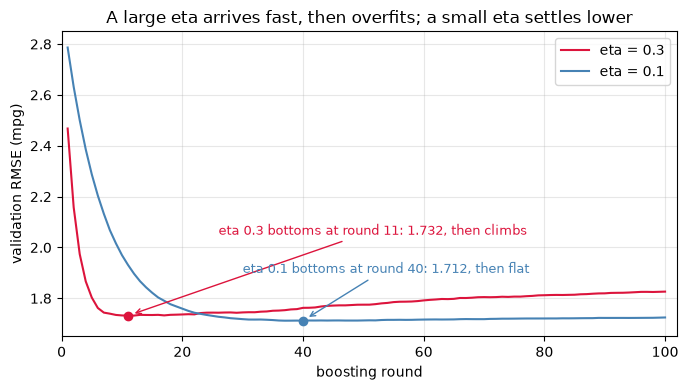

validation RMSE every 10 rounds:
 round  eta=0.3  eta=0.1
     1    2.468    2.786
    11    1.732    1.932
    21    1.738    1.751
    31    1.745    1.717
    41    1.763    1.713
    51    1.775    1.714
    61    1.794    1.717
    71    1.804    1.719
    81    1.813    1.721
    91    1.821    1.723


In [26]:
fig, ax = plt.subplots()

ax.plot(df_03["round"], df_03["val_rmse"], label="eta = 0.3", color="crimson")
ax.plot(df_01["round"], df_01["val_rmse"], label="eta = 0.1", color="steelblue")

ax.scatter([best_row["round"]], [best_row["val_rmse"]], color="crimson", zorder=5)
ax.scatter([best_row_01["round"]], [best_row_01["val_rmse"]], color="steelblue", zorder=5)

ax.annotate(
    f"eta 0.3 bottoms at round {int(best_row['round'])}: {best_row['val_rmse']:.3f}, then climbs",
    xy=(best_row["round"], best_row["val_rmse"]),
    xytext=(26, 2.05), color="crimson", fontsize=9,
    arrowprops=dict(arrowstyle="->", color="crimson", lw=1, shrinkB=5),
)
ax.annotate(
    f"eta 0.1 bottoms at round {int(best_row_01['round'])}: {best_row_01['val_rmse']:.3f}, then flat",
    xy=(best_row_01["round"], best_row_01["val_rmse"]),
    xytext=(30, 1.9), color="steelblue", fontsize=9,
    arrowprops=dict(arrowstyle="->", color="steelblue", lw=1, shrinkB=5),
)

ax.set_ylim(1.65, 2.85)
ax.set_xlim(0, 102)
ax.set_xlabel("boosting round")
ax.set_ylabel("validation RMSE (mpg)")
ax.set_title("A large eta arrives fast, then overfits; a small eta settles lower")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("validation RMSE every 10 rounds:")
print(pd.DataFrame({
    "round": df_03["round"][::10],
    "eta=0.3": df_03["val_rmse"][::10].round(3),
    "eta=0.1": df_01["val_rmse"][::10].round(3),
}).to_string(index=False))

Read the red curve (0.3): it falls steeply, bottoms at **1.732 at round 11**, and then *rises* for the
remaining 89 rounds while training RMSE marches down to **0.901**. That is textbook overfitting — after round
11 the model is memorizing, not learning. Read the blue curve (0.1): it descends more slowly, passes the red
curve, bottoms at **1.712 at round 40**, and then holds flat, finishing at 1.725. Both its floor and its
100-round value are better.

That is the entire lesson of `eta`:

- **eta controls speed, and speed is not accuracy.** `eta=0.3` reaches its best score sooner and then spends
  89 rounds ruining it. At a *fixed* 100 rounds, the patient model wins.
- **the homework compares the models at the round-100 checkpoint**, which is why the answer is 0.1 and not a
  tie. If both had been allowed early stopping, 0.3 would also stop at ~1.73, and 0.1 would still win.
- **in practice you would pair a small eta with more rounds and early stopping** — `early_stopping_rounds`
  watches the validation curve and stops when it turns up, which is how you avoid picking the stopping point
  by eye. Section 11 asks you to run it.

> Notice the asymmetry with the random forest: adding trees there never hurt (section 5); adding rounds here
> hurts after round 11 at `eta=0.3`. Sequential correction of residuals is powerful, and that power is exactly
> why it needs a validation set watching it.


## 9. One honest number: refit on train + validation, then test once

Everything so far compared models on the validation set — that is what validation is for. To produce a final
estimate, refit the chosen configuration on **train + validation** (8,000 rows, everything the model is allowed
to see) with a vectorizer fitted on that same data, and score the **test set exactly once**.

Two models are worth carrying forward: the random forest at its tuned setting (`100` trees, `max_depth=10`),
and XGBoost at `eta=0.1` for 100 rounds.

In [27]:
# Re-fit the encoder on train + validation, then apply the identical transform to test
dv_full = DictVectorizer(sparse=True)
X_full_train = dv_full.fit_transform(df_full_train.to_dict(orient="records"))
X_test = dv_full.transform(df_test.to_dict(orient="records"))

assert list(dv_full.get_feature_names_out()) == feature_names, "encoded columns changed"

rf_final = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=1, n_jobs=-1)
rf_final.fit(X_full_train, y_full_train)
pred_rf_test = rf_final.predict(X_test)

bst_final = xgb.train(xgb_params_slow, xgb.DMatrix(X_full_train, label=y_full_train),
                      num_boost_round=100, verbose_eval=False)
pred_xgb_test = bst_final.predict(xgb.DMatrix(X_test))

print(f"random forest (100 trees, depth 10): test RMSE = {rmse(y_test, pred_rf_test):.3f}")
print(f"xgboost (eta 0.1, 100 rounds):       test RMSE = {rmse(y_test, pred_xgb_test):.3f}")

random forest (100 trees, depth 10): test RMSE = 1.671
xgboost (eta 0.1, 100 rounds):       test RMSE = 1.656


In [28]:
mean_baseline_test = rmse(y_test, np.full_like(y_test, y_full_train.mean()))
rf_valid = df_grid.query("max_depth == 10 and n_estimators == 100")["val_rmse"].iloc[0]

summary = pd.DataFrame([
    {"model": "constant (training mean)",
     "validation_rmse": rmse(y_val, np.full_like(y_val, y_train.mean())),
     "test_rmse": mean_baseline_test},
    {"model": "decision stump (depth 1)",
     "validation_rmse": rmse(y_val, dt.predict(X_val)),
     "test_rmse": np.nan},
    {"model": "random forest (10 trees)",
     "validation_rmse": rmse(y_val, pred_rf10),
     "test_rmse": np.nan},
    {"model": "random forest (100 trees, depth 10)",
     "validation_rmse": rf_valid,
     "test_rmse": rmse(y_test, pred_rf_test)},
    {"model": "xgboost (eta 0.1, 100 rounds)",
     "validation_rmse": df_01["val_rmse"].iloc[-1],
     "test_rmse": rmse(y_test, pred_xgb_test)},
])

summary["explained_vs_baseline"] = (1 - summary["test_rmse"] / mean_baseline_test).round(3)
print(summary.round(3).to_string(index=False))

                              model  validation_rmse  test_rmse  explained_vs_baseline
           constant (training mean)            2.960      2.898                  0.000
           decision stump (depth 1)            2.673        NaN                    NaN
           random forest (10 trees)            1.839        NaN                    NaN
random forest (100 trees, depth 10)            1.744      1.671                  0.423
      xgboost (eta 0.1, 100 rounds)            1.725      1.656                  0.429


**The result.** On cars the model has never seen:

| Model | validation RMSE | test RMSE | error removed vs. mean |
|---|---:|---:|---:|
| constant (training mean) | 2.960 | 2.898 | — |
| decision stump (depth 1) | 2.673 | — | 10% |
| random forest, 10 trees | 1.839 | — | 38% |
| random forest, 100 trees, depth 10 | 1.744 | **1.671** | 42% |
| xgboost, eta 0.1, 100 rounds | 1.725 | **1.656** | 43% |

Both final models land around **1.66–1.67 mpg** of error on a target with a standard deviation of ~2.9 —
close to **R² ≈ 0.67** on the test set. The two are statistically indistinguishable on 2,000
test cars; on this split XGBoost is ahead by 0.015 mpg, which is well inside the noise of a single split.

A predicted-vs-actual plot is the regression analogue of the ROC curve: perfect predictions lie on the
diagonal, and systematic bending away from it means the model is biased low at one end or high at the other.

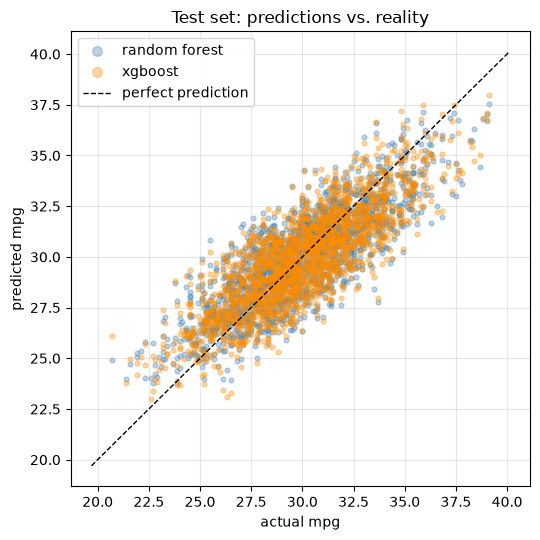

xgboost residuals: mean -0.046 mpg, sd 1.655 mpg
worst under-prediction: -5.72 mpg
worst over-prediction:  +5.39 mpg


In [29]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))

ax.scatter(y_test, pred_rf_test, s=12, alpha=0.35, label="random forest", color="steelblue")
ax.scatter(y_test, pred_xgb_test, s=12, alpha=0.35, label="xgboost", color="darkorange")
lims = [y_test.min() - 1, y_test.max() + 1]
ax.plot(lims, lims, color="black", linestyle="--", linewidth=1, label="perfect prediction")

ax.set_xlabel("actual mpg")
ax.set_ylabel("predicted mpg")
ax.set_title("Test set: predictions vs. reality")
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

residuals = pred_xgb_test - y_test
print(f"xgboost residuals: mean {residuals.mean():+.3f} mpg, sd {residuals.std():.3f} mpg")
print(f"worst under-prediction: {residuals.min():+.2f} mpg")
print(f"worst over-prediction:  {residuals.max():+.2f} mpg")

The cloud hugs the diagonal across the whole range, with a slight squeeze at the top: the very economical
cars are under-predicted, because there are so few of them (only **36 of 10,000** cars reach 38 mpg or more)
and the trees prefer a conservative average. The residual mean is essentially zero — **−0.05 mpg**, i.e. no
systematic bias — and the spread is symmetric, which is what a well-behaved squared-error model should look
like. The worst single miss is under six mpg in either direction.

> **Variance of a single split, honestly.** The validation and test columns differ by 0.05–0.07 mpg for the
> same model. That is not the model changing; it is 2,000 cars being a different 2,000 cars. If you need to
> rank two models that are within ~0.05 mpg of each other, a single split cannot do it — you need the
> cross-validation of section 11. Do not over-interpret the XGBoost "win" above.


## 10. Summary

### 10.1 The answers, with the reasoning that produces them

| # | Question | Answer | Why |
|---|---|---|---|
| 1 | feature used by a depth-1 tree | **`model_year`** | the single best variance cut on this data; one-hot columns map back with `name.split("=")[0]` |
| 2 | validation RMSE, 10-tree forest | **1.837** | computed 1.839; 38% better than the 2.96 mean baseline |
| 3 | best `n_estimators` | **100** | 1.768 at 3 dp; 150 ties and is 0.0005 worse at 6 dp |
| 4 | best `max_depth` by mean RMSE | **10** | 1.754 vs 1.784 / 1.788 / 1.787; wins at every forest size |
| 5 | most important offered feature | **`vehicle_weight`** | 0.203 vs 0.079 horsepower, 0.061 displacement, 0.055 acceleration |
| 6 | better `eta` at 100 rounds | **0.1** | 1.725 vs 1.826; `eta=0.3` overfits after round 11 |

### 10.2 What this homework actually taught

1. **A tree is a greedy sequence of threshold questions, and depth is the complexity dial.** One split
   explains 10% of the error; ten deep trees explain 38%; the tuned forest explains 42% on unseen cars.
2. **Ensembles trade the right kind of variance away.** Random forests average *independent* trees, so more
   trees never hurt — that is why question 3's curve flattens instead of turning up.
3. **Deeper is not better.** Between depth 10 and 25 the error *rose*, because deeper trees agree with each
   other more and the averaging stops paying. The grid in question 4, not the single number, is the evidence.
4. **Feature importance is a question about the model, not about the world.** Impurity importance put
   `model_year` first and `vehicle_weight` second; permutation importance agreed on the top two but promoted
   `fuel_type`. Neither is wrong; both need their caveats attached.
5. **Learning rate is a speed/patience trade.** At a fixed budget of 100 rounds, the patient model wins;
   with early stopping both would stop near their own floor, and the gap narrows. Reporting a boosting model
   without a validation curve is reporting a number you cannot defend.

### 10.3 Where the remaining error lives

Nothing in this notebook gets below ~1.65 mpg, and no amount of tuning will, because the ceiling is the data:
fuel economy depends on driving style, gearing, aerodynamics, fuel blend and maintenance, none of which are
columns here. What you *can* still do is attack the two weakest links:

- the 1,141 cars with `horsepower`/`acceleration` filled with `0`, which teaches the model a false extreme;
- the single 60/20/20 split, which cannot distinguish two models 0.05 mpg apart.

Both are exercises 1 and 4 below.


## 11. Exercises and further exploration

Ordered from "change one line" to "build something new". Work in a copy so the answers above stay intact.

### Warm-up

1. **Change the split seed.** Set both `random_state` values in the split calls to `42` and rerun question 2.
   How far does the validation RMSE move? Compare that movement with the 0.05–0.07 mpg gap between
   validation and test for the same model. Is the answer still 1.837?
2. **`max_depth=1` with a different loss.** Fit `DecisionTreeRegressor(max_depth=1, criterion="absolute_error")`.
   Does it still split on `model_year`, and at the same threshold? Which cars move sides, and why would a
   median-based criterion prefer a different cut?

### Replace the weak link: missing values

3. **Median + missing flag.** Instead of `fillna(0)`, add `horsepower_is_missing` / `acceleration_is_missing`
   as boolean columns, fill the gaps with the **training** median, and rerun questions 2 and 5.
   How much does validation RMSE improve, and does `vehicle_weight` stay the most important of the four?
   (Remember: compute the median on train only — computing it on all rows is a small leak.)

### Replace the weak link: evaluation

4. **Cross-validation instead of one split.** With `KFold(n_splits=5, shuffle=True, random_state=1)` and
   `cross_val_score(..., scoring="neg_root_mean_squared_error")` on `df_full_train`, compare
   random forest (100, depth 10) against XGBoost (eta 0.1, 100 rounds). Report mean ± std. Is the 0.015 mpg
   "win" from section 9 inside one standard deviation? This is the correct way to settle a question that a
   single test set cannot.
5. **A learning curve.** Plot validation RMSE against training-set size (25%, 50%, 75%, 100%). If the curve is
   still falling at 100%, more data would help; if it is flat, the model has hit its ceiling.

### Push the models

6. **Early stopping for real.** Start from `xgb_params_slow`, set `eta=0.05`, and call
   `xgb.train(params, dtrain, num_boost_round=1000, evals=[(dval, "val")], early_stopping_rounds=20)`.
   Read `bst.best_iteration`, refit on train + validation for that many rounds, and compare with section 9's
   1.656. Expect about **84 rounds and 1.64 mpg**: a real but small gain, in line with what the validation
   curve promised — and nothing like the 0.1 mpg that moving `eta` from 0.3 to 0.1 bought.
7. **Tune `max_features`.** The forest's other randomness knob. Try `"sqrt"`, `0.5`, `1.0` at 100 trees and
   depth 10. Lower `max_features` decorrelates the trees — does the error drop, and does it change the
   importance ranking?
8. **Boost with a linear base learner.** `xgb.train({..., "booster": "gblinear"})` and compare. Boosting
   linear models is a good demonstration of what trees add: interactions. Where does the linear model fail on
   the predicted-vs-actual plot?

### Go further

9. **Grouped importance.** Sum the one-hot importances of `origin`, `fuel_type` and `drivetrain` into three
   aggregate columns, then re-rank all 10 original features. Which of the *categorical* features is more
   important than `acceleration`? Does the answer change the story from question 5?
10. **A per-segment error analysis.** Bucket the test set by `origin` or `model_year` decade and compute RMSE
    within each bucket. If one segment is much worse, that is a modelling conclusion a single global RMSE
    hides — and it is the kind of thing a stakeholder will ask about before trusting the model.
